In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [2]:
data = pd.read_csv("cars_data.csv")
df = pd.DataFrame(data)
df

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize,Manufacturer
0,I10,2017,7495.0,Manual,11630,Petrol,145,60.1,1.0,hyundi
1,Polo,2017,10989.0,Manual,9200,Petrol,145,58.9,1.0,volkswagen
2,2 Series,2019,27990.0,Semi-Auto,1614,Diesel,145,49.6,2.0,BMW
3,Yeti Outdoor,2017,12495.0,Manual,30960,Diesel,150,62.8,2.0,skoda
4,Fiesta,2017,7999.0,Manual,19353,Petrol,125,54.3,1.2,ford
...,...,...,...,...,...,...,...,...,...,...
97707,Fiesta,2017,10447.0,Automatic,8337,Petrol,145,54.3,1.0,ford
97708,3 Series,2014,14995.0,Manual,25372,Diesel,30,61.4,2.0,BMW
97709,Fiesta,2017,8950.0,Manual,19910,Petrol,125,54.3,1.2,ford
97710,Astra,2017,10700.0,Automatic,24468,Petrol,125,50.4,1.4,vauxhall


In [3]:
df.head()

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize,Manufacturer
0,I10,2017,7495.0,Manual,11630,Petrol,145,60.1,1.0,hyundi
1,Polo,2017,10989.0,Manual,9200,Petrol,145,58.9,1.0,volkswagen
2,2 Series,2019,27990.0,Semi-Auto,1614,Diesel,145,49.6,2.0,BMW
3,Yeti Outdoor,2017,12495.0,Manual,30960,Diesel,150,62.8,2.0,skoda
4,Fiesta,2017,7999.0,Manual,19353,Petrol,125,54.3,1.2,ford


In [4]:
df.shape

(97712, 10)

In [5]:
df.describe()

,year,price,mileage,tax,mpg,engineSize
count,97712.000000,96727.000000,97712.000000,97712.000000,94256.000000,97712.000000
mean,2017.066502,16774.299823,23219.475499,120.142408,55.228326,1.664913
std,2.118661,9874.715050,21060.882301,63.357250,16.296400,0.558574
min,1970.000000,450.000000,1.000000,0.000000,0.300000,0.000000
25%,2016.000000,9999.000000,7673.000000,125.000000,47.100000,1.200000
50%,2017.000000,14471.000000,17682.500000,145.000000,54.300000,1.600000
75%,2019.000000,20750.000000,32500.000000,145.000000,62.800000,2.000000
max,2024.000000,159999.000000,323000.000000,580.000000,470.800000,6.600000


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 97712 entries, 0 to 97711
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   model         97712 non-null  str    
 1   year          97712 non-null  int64  
 2   price         96727 non-null  float64
 3   transmission  97712 non-null  str    
 4   mileage       97712 non-null  int64  
 5   fuelType      93586 non-null  str    
 6   tax           97712 non-null  int64  
 7   mpg           94256 non-null  float64
 8   engineSize    97712 non-null  float64
 9   Manufacturer  97712 non-null  str    
dtypes: float64(3), int64(3), str(4)
memory usage: 9.8 MB


In [7]:
df.isna().sum()

model              0
year               0
price            985
transmission       0
mileage            0
fuelType        4126
tax                0
mpg             3456
engineSize         0
Manufacturer       0
dtype: int64

In [8]:
# filling missing values "Gender"
df["tax"] = df["tax"].fillna(df["tax"].mode()[0])

In [9]:
df["mpg"] = df["mpg"].fillna(df["mpg"].median())

In [10]:
df["fuelType"] = df["mpg"].fillna(df["mpg"].mode()[0])

In [11]:
df = df.dropna(subset=['price']).copy()

In [12]:
df.isna().sum()

model           0
year            0
price           0
transmission    0
mileage         0
fuelType        0
tax             0
mpg             0
engineSize      0
Manufacturer    0
dtype: int64

In [13]:
df.duplicated().sum()

np.int64(0)

In [14]:
df = df.drop_duplicates()

In [15]:
df.duplicated().sum()

np.int64(0)

In [16]:
df.columns

Index(['model', 'year', 'price', 'transmission', 'mileage', 'fuelType', 'tax',
       'mpg', 'engineSize', 'Manufacturer'],
      dtype='str')

In [17]:
cols = ['model', 'year', 'transmission', 'mileage', 'fuelType', 'tax',
       'mpg', 'engineSize', 'Manufacturer']
for col in cols:
  print(f"\n{col}\n",df[col].value_counts())



model
 model
 Fiesta     6441
 Golf       4729
 Focus      4509
 C Class    3659
 Corsa      3243
            ... 
 A2            1
 Amica         1
 RS7           1
 Accent        1
220            1
Name: count, Length: 196, dtype: int64

year
 year
2019    25884
2017    21403
2016    15576
2018    13429
2015     7515
2014     4014
2020     4009
2013     2561
2012      622
2011      427
2010      337
2009      273
2008      197
2007      162
2006       85
2005       67
2004       51
2003       34
2002       30
2001       20
2000        9
1998        7
1999        6
1997        4
1996        2
1970        2
2024        1
Name: count, dtype: int64

transmission
 transmission
Manual       54949
Semi-Auto    22071
Automatic    19698
Other            9
Name: count, dtype: int64

mileage
 mileage
10       639
5000     638
1000     613
6000     453
3000     364
        ... 
10453      1
27194      1
22635      1
25570      1
25372      1
Name: count, Length: 42004, dtype: int64

fuelType
 f


mpg
 mpg
54.30    6250
60.10    5895
65.70    4508
64.20    3449
51.40    3413
         ... 
22.30       1
25.90       1
44.60       1
11.00       1
42.16       1
Name: count, Length: 204, dtype: int64

engineSize
 engineSize
2.0    26595
1.0    16945
1.5    11125
1.4    10774
1.6     8605
1.2     6645
3.0     5356
2.1     3944
1.8     1696
1.3     1290
1.7      897
1.1      550
2.2      464
2.5      447
4.0      350
0.0      262
2.9      167
2.3      144
4.4       79
2.4       71
5.0       51
5.5       44
2.8       41
1.9       27
3.2       26
4.2       25
4.7       24
5.2       23
3.5       20
6.2       13
2.7        8
0.6        7
6.0        2
6.6        2
3.7        2
4.1        2
5.4        1
4.5        1
4.3        1
6.3        1
Name: count, dtype: int64

Manufacturer
 Manufacturer
ford          17628
volkswagen    14740
vauxhall      13119
merc          12737
BMW           10563
Audi          10453
toyota         6626
skoda          6131
hyundi         4730
Name: count, dtype:

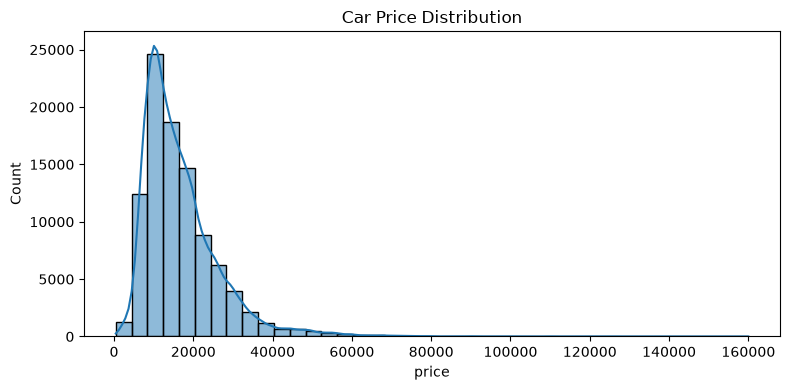

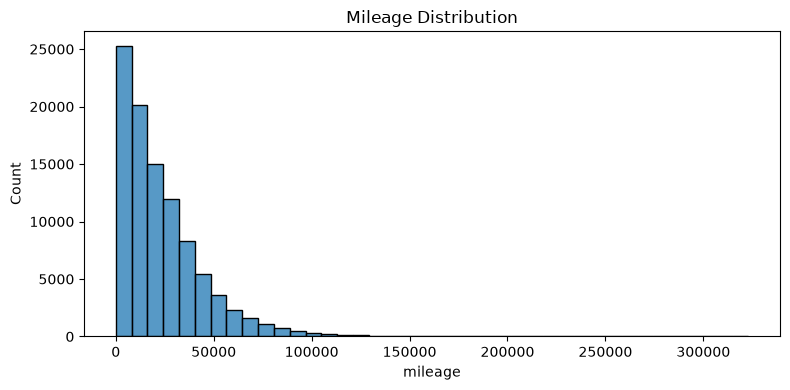

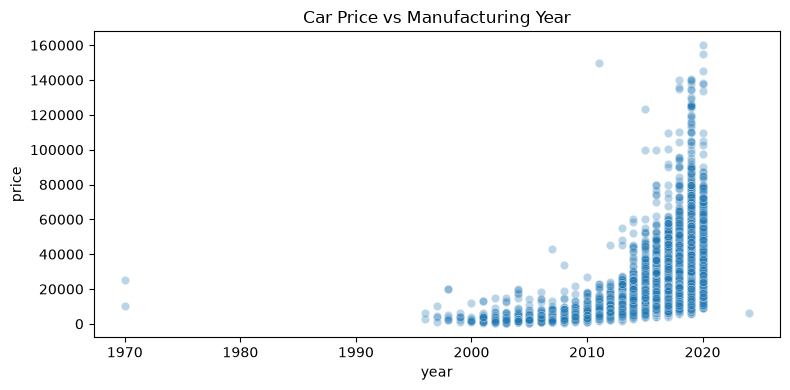

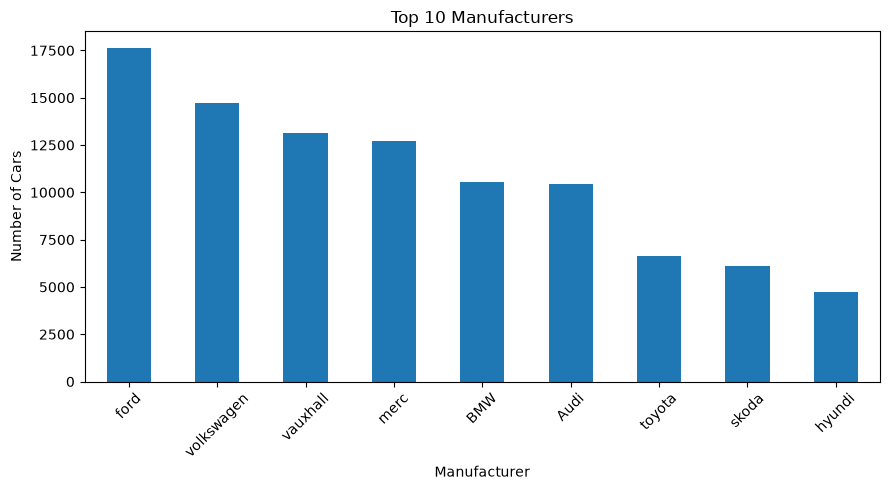

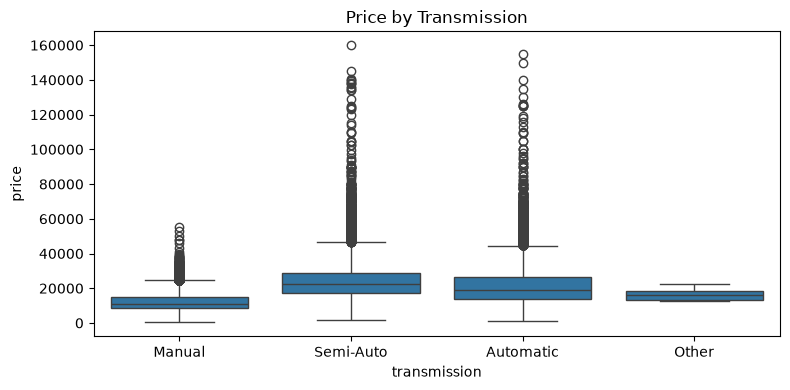

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Price distribution
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x='price', bins=40, kde=True)
plt.title('Car Price Distribution')
plt.tight_layout()
plt.show()

# 2. Mileage distribution
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x='mileage', bins=40)
plt.title('Mileage Distribution')
plt.tight_layout()
plt.show()

# 3. Price vs year
plt.figure(figsize=(8, 4))
sns.scatterplot(data=df, x='year', y='price', alpha=0.3)
plt.title('Car Price vs Manufacturing Year')
plt.tight_layout()
plt.show()

# 4. Top 10 manufacturers
plt.figure(figsize=(9, 5))
df['Manufacturer'].value_counts().head(10).plot(kind='bar')
plt.title('Top 10 Manufacturers')
plt.ylabel('Number of Cars')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 5. Price by transmission
plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x='transmission', y='price')
plt.title('Price by Transmission')
plt.tight_layout()
plt.show()

In [19]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

cat_cols = df.select_dtypes(
    include=['object', 'category']
).columns

for col in cat_cols:
    df[col] = le.fit_transform(df[col].astype(str))

df.head()

C:\Users\arjun\AppData\Local\Temp\ipykernel_11232\2731377127.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(


,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize,Manufacturer
0,81,2017,7495.0,1,11630,60.1,145,60.1,1.0,3
1,115,2017,10989.0,1,9200,58.9,145,58.9,1.0,8
2,1,2019,27990.0,3,1614,49.6,145,49.6,2.0,1
3,184,2017,12495.0,1,30960,62.8,150,62.8,2.0,5
4,60,2017,7999.0,1,19353,54.3,125,54.3,1.2,2


In [20]:
df.corr()


,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize,Manufacturer
model,1.000000,0.034455,0.047465,-0.032930,-0.051039,-0.122795,0.109557,-0.122795,-0.006226,0.310840
year,0.034455,1.000000,0.492507,0.142996,-0.739838,-0.128775,0.192684,-0.128775,-0.035038,0.015302
price,0.047465,0.492507,1.000000,0.240633,-0.417827,-0.290041,0.307025,-0.290041,0.639612,-0.224655
transmission,-0.032930,0.142996,0.240633,1.000000,-0.125780,-0.106761,0.073586,-0.106761,0.149879,-0.071622
mileage,-0.051039,-0.739838,-0.417827,-0.125780,1.000000,0.180082,-0.215543,0.180082,0.107362,-0.037130
fuelType,-0.122795,-0.128775,-0.290041,-0.106761,0.180082,1.000000,-0.443427,1.000000,-0.246146,-0.014994
tax,0.109557,0.192684,0.307025,0.073586,-0.215543,-0.443427,1.000000,-0.443427,0.281216,-0.049960
mpg,-0.122795,-0.128775,-0.290041,-0.106761,0.180082,1.000000,-0.443427,1.000000,-0.246146,-0.014994
engineSize,-0.006226,-0.035038,0.639612,0.149879,0.107362,-0.246146,0.281216,-0.246146,1.000000,-0.220691
Manufacturer,0.310840,0.015302,-0.224655,-0.071622,-0.037130,-0.014994,-0.049960,-0.014994,-0.220691,1.000000


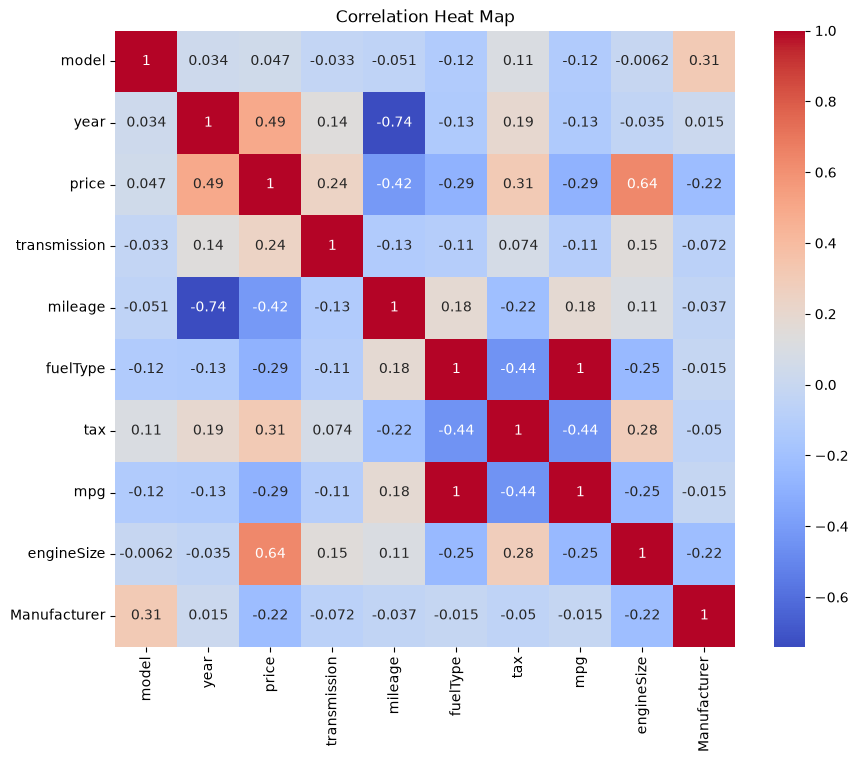

In [21]:
plt.figure(figsize=(10,8))
sns.heatmap(df.corr(),annot=True,cmap="coolwarm")
plt.title("Correlation Heat Map")
plt.show()

In [22]:
# Multi-Class Classification: Discretizing Price into 3 Market Segments
# Continuous price has >13,000 distinct values. We discretize into 3 balanced tiers:
# Budget (< ~$10.5k), Mid-Range ($10.5k - $19k), and Luxury (> $19k)
df["price_tier"] = pd.qcut(df["price"], q=3, labels=["Budget", "Mid-Range", "Luxury"])

X = df.drop(["price", "price_tier"], axis=1)
y = df["price_tier"]
print("Feature shape X:", X.shape)
print("Target tier distribution:\n", y.value_counts())


Feature shape X: (96727, 9)
Target tier distribution:
 price_tier
Budget       32296
Luxury       32241
Mid-Range    32190
Name: count, dtype: int64


In [23]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.3,random_state = 42)


In [24]:
from sklearn.ensemble import RandomForestClassifier

# Train Random Forest Classifier on Price Tiers
model = RandomForestClassifier(n_estimators=100, max_depth=15, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("Random Forest Classifier trained successfully.")


Random Forest Classifier trained successfully.


In [25]:
from sklearn.metrics import confusion_matrix
print(confusion_matrix(y_test,y_pred))

[[9097    0  717]
 [   7 8880  646]
 [ 686  582 8404]]


In [26]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))


              precision    recall  f1-score   support

      Budget       0.93      0.93      0.93      9814
      Luxury       0.94      0.93      0.93      9533
   Mid-Range       0.86      0.87      0.86      9672

    accuracy                           0.91     29019
   macro avg       0.91      0.91      0.91     29019
weighted avg       0.91      0.91      0.91     29019

